# CityLens · Sorocaba — Pipeline no Google Colab

**Como usar (não precisa instalar nada no seu PC):**
1. No menu de cima: **Ambiente de execução → Executar tudo** (ou `Ctrl+F9`).
2. Espere ~2–4 min. No fim aparece o **mapa das 6 zonas** e uma tabela.

Este notebook baixa a malha de setores censitários do **IBGE** (via `geobr`),
descobre a posição de cada bairro pelo **OpenStreetMap** e atribui cada setor à
**zona do bairro mais próximo**. As 6 zonas são as oficiais do zoneamento da
Prefeitura/Urbes. Regra do projeto: **não inventar dado** — bairro que não for
encontrado é avisado e ignorado, nunca chutado.


In [1]:
# 1) Instala as bibliotecas (só nesta sessão do Colab)
!pip -q install geobr geopandas matplotlib requests 2>/dev/null
print("Bibliotecas prontas.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 43.6 MB/s eta 0:00:00
Bibliotecas prontas.


In [2]:
# 2) As 6 zonas oficiais e seus bairros (transcritos do mapa oficial)
ZONAS = {
    "centro": {
        "nome": "Centro",
        "bairros": [
            "Centro"
        ]
    },
    "norte": {
        "nome": "Zona Norte",
        "bairros": [
            "Jardim Botucatu",
            "Jardim Maria Eugênia",
            "Parque Laranjeiras",
            "Jardim Guaíba",
            "Jardim São Guilherme",
            "Jardim Santa Marina",
            "Parque São Bento",
            "Jardim Novo Horizonte",
            "Jardim Maria Antônia Prado",
            "Jardim Guadalupe",
            "Vila Nova Sorocaba",
            "Vila Angélica",
            "Jardim Húngaros",
            "Jardim Brasilândia",
            "Vila Fiori",
            "Jardim Maria do Carmo",
            "Vila Gabriel",
            "Vila Progresso",
            "Vila Porto",
            "Vila Rica",
            "Parque Vitória Régia",
            "Retiro São João",
            "Jardim Iguatemi",
            "Jardim Morumbi",
            "Jardim Leocádia",
            "Vila Cardoso",
            "Vila Barão",
            "Vila Nova Esperança",
            "Jardim Zulmira",
            "Jardim Simus",
            "Jardim Vera Cruz",
            "Santa Terezinha",
            "Vila Trujillo",
            "Vila Carvalho",
            "Vila Santana",
            "Jardim Santa Rosália"
        ]
    },
    "oeste": {
        "nome": "Zona Oeste",
        "bairros": [
            "Jardim Santa Bárbara",
            "Júlio de Mesquita Filho",
            "Jardim Wanel Ville",
            "Parque Esmeralda",
            "Jardim Ouro Fino",
            "Parque Ouro Fino",
            "Parque Manchester",
            "Central Parque",
            "Largo do Divino",
            "Jardim São Paulo"
        ]
    },
    "sul": {
        "nome": "Zona Sul",
        "bairros": [
            "Vila Jardini",
            "Jardim Magnólia",
            "Jardim Paulistano",
            "Jardim Europa",
            "Jardim dos Estados",
            "Jardim América",
            "Jardim Portal da Colina",
            "Jardim Emília",
            "Jardim Sandra",
            "Parque da Biquinha",
            "Vila Assis",
            "Parque Água Vermelha",
            "Jardim Guadalajara",
            "Jardim São Carlos",
            "Parque Campolim"
        ]
    },
    "leste": {
        "nome": "Zona Leste",
        "bairros": [
            "Jardim Gonçalves",
            "Jardim Sol",
            "Jardim Bandeirantes",
            "Jardim Piratininga",
            "Jardim Granja",
            "Vila Haro",
            "Parque Três Meninos",
            "Vila Hortência",
            "Jardim Gutierres",
            "Jardim Prestes de Barros",
            "Vila Colorau",
            "Vila Barcelona",
            "Jardim Parada do Alto"
        ]
    },
    "industrial": {
        "nome": "Zona Industrial",
        "bairros": [
            "Aparecidinha",
            "Brigadeiro Tobias",
            "Alto da Boa Vista",
            "Parque Chico Mendes"
        ]
    }
}

import math, time, json, requests

def dist_km(lon1, lat1, lon2, lat2):
    """Distância aproximada (equiretangular) em km — ótima em escala de cidade."""
    R = 6371.0
    x = math.radians(lon2 - lon1) * math.cos(math.radians((lat1 + lat2)/2))
    y = math.radians(lat2 - lat1)
    return R * math.hypot(x, y)

def atribuir_por_proximidade(setores_xy, pontos):
    """Cada setor (id, lon, lat) recebe a zona do bairro mais próximo."""
    out = []
    for sid, slon, slat in setores_xy:
        melhor = None
        for zona, bairro, blon, blat in pontos:
            d = dist_km(slon, slat, blon, blat)
            if melhor is None or d < melhor[0]:
                melhor = (d, zona, bairro)
        out.append({"id": sid, "zona": melhor[1], "bairro": melhor[2],
                    "dist_km": round(melhor[0], 3)})
    return out

print("Funções de recorte carregadas.")

Funções de recorte carregadas.


In [3]:
# 3) Baixa a malha de setores censitários de Sorocaba (IBGE, via geobr)
import geobr, warnings
warnings.filterwarnings("ignore")
COD_SOROCABA = 3552205
try:
    setores = geobr.read_census_tract(code_tract=COD_SOROCABA, year=2022,
                                      simplified=False, showProgress=False)
except TypeError:
    # versões diferentes do geobr usam nomes de parâmetro distintos
    setores = geobr.read_census_tract(code_tract=COD_SOROCABA, year=2022)
setores = setores.to_crs(4326)
col_id = next((c for c in ["code_tract","CD_SETOR","CD_GEOCODI"] if c in setores.columns),
              setores.columns[0])
setores["CD_SETOR"] = setores[col_id].astype(str)
print(f"Setores de Sorocaba: {len(setores):,}")
setores.head(3)

censustracts_2022_simplified.parquet: 100%|██████████| 381M/381M [00:03<00:00, 99.6MB/s]


Setores de Sorocaba: 1,148


,code_tract,code_muni,name_muni,code_neighborhood,name_neighborhood,code_district,name_district,code_subdistrict,name_subdistrict,code_weighting,zone,code_state,abbrev_state,name_state,code_region,name_region,year,geometry,CD_SETOR
0,3.552205e+14,3552205.0,Sorocaba,NaN,None,355220505.0,Sorocaba,3.552205e+10,None,3.552205e+09,urbano,35.0,SP,São Paulo,3.0,Sudeste,2022.0,"MULTIPOLYGON (((-47.4558 -23.4985, -47.4569 -2...",355220505000001.0
1,3.552205e+14,3552205.0,Sorocaba,NaN,None,355220505.0,Sorocaba,3.552205e+10,None,3.552205e+09,urbano,35.0,SP,São Paulo,3.0,Sudeste,2022.0,"MULTIPOLYGON (((-47.45252 -23.50157, -47.45274...",355220505000002.0
2,3.552205e+14,3552205.0,Sorocaba,NaN,None,355220505.0,Sorocaba,3.552205e+10,None,3.552205e+09,urbano,35.0,SP,São Paulo,3.0,Sudeste,2022.0,"MULTIPOLYGON (((-47.45667 -23.49986, -47.45878...",355220505000003.0


In [21]:
# 4) Descobre a posição (lat/lon) de cada bairro pelo OpenStreetMap (Nominatim)
#    Regras (não inventar dado):
#    (a) só vale resultado DENTRO do contorno de Sorocaba (união dos setores do IBGE);
#    (b) o NOME no OSM tem que bater com o bairro, ignorando "Jardim/Vila/Parque", "de/da" e
#        numerais (ex.: "Jardim Simus II" = "Jardim Simus"); parque só se o Nominatim o reconhecer;
#    (c) tem que ser bairro (suburb/neighbourhood/...) ou parque homônimo — obra, igreja, loja: não;
#    (d) nome que casa com bairros DIFERENTES (ex.: "Jardim Granja" -> Granja Olga e Granja Deolinda)
#        é ambíguo e fica de fora.
#    Qualquer regra falhou -> bairro ignorado e avisado.
import re, unicodedata
from shapely.geometry import Point
CONTORNO = setores.geometry.union_all() if hasattr(setores.geometry, "union_all") else setores.unary_union
TIPOS_BAIRRO = {"suburb", "neighbourhood", "quarter", "city_block", "residential", "hamlet", "village"}
ACEITOS = TIPOS_BAIRRO | {"park"}

# Grafia usada no OpenStreetMap quando difere da lista acima (conferido no OSM)
NOME_NO_OSM = {
    "Jardim Húngaros": "Jardim Hungarês",
    "Jardim Sol": "Jardim do Sol",
    "Jardim Gutierres": "Jardim João Gutierres",  # único "Gutierres" no OSM; fica na Zona Leste
}

def norm(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", s)).strip()

GENERICOS = {"jardim", "jd", "vila", "parque", "conjunto", "habitacional", "residencial",
             "bairro", "loteamento", "gleba", "bleba", "chacara", "chacaras", "recanto", "nucleo",
             "da", "das", "de", "do", "dos", "e", "i", "ii", "iii", "iv", "v", "vi", "vii", "viii"}

def nucleo(s):
    """Palavras que identificam o bairro (sem 'Jardim', 'Vila', 'de', numerais, letras soltas)."""
    return {t for t in norm(s).split() if t not in GENERICOS and len(t) > 1 and not t.isdigit()}

CACHE = "/content/geocode_bairros_v3.json"   # guarda os resultados brutos (dentro do contorno)
try:
    cache = json.load(open(CACHE, encoding="utf-8"))
except Exception:
    cache = {}
headers = {"User-Agent": "CityLens-Sorocaba/1.0 (projeto escolar)"}

def buscar(nome):
    if nome not in cache:
        r = requests.get("https://nominatim.openstreetmap.org/search",
                         params={"q": f"{nome}, Sorocaba, SP, Brasil", "format": "jsonv2",
                                 "limit": 10, "countrycodes": "br"},
                         headers=headers, timeout=25)
        cache[nome] = [{"lon": float(x["lon"]), "lat": float(x["lat"]),
                        "tipo": x.get("addresstype") or x.get("type"),
                        "nome": x.get("name") or x["display_name"].split(",")[0]}
                       for x in r.json()
                       if CONTORNO.contains(Point(float(x["lon"]), float(x["lat"])))]
        json.dump(cache, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False)
        time.sleep(1.1)  # política do Nominatim: no máx. 1 pedido por segundo
    return cache[nome]

def localizar(bairro):
    """Devolve ((lon, lat), None) ou (None, motivo)."""
    alvo = NOME_NO_OSM.get(bairro, bairro)
    try:
        res = buscar(alvo)
    except Exception as e:
        return None, f"erro de rede ({e})"
    alvo_nuc = nucleo(alvo)
    # (b) mesmo núcleo de nome: "Parque das Laranjeiras" = "Parque Laranjeiras",
    #     "Jardim Morumbi I e II" = "Jardim Morumbi"; mas "Granja Olga" != "Granja"
    cands = [r for r in res if r["tipo"] in ACEITOS and nucleo(r["nome"]) == alvo_nuc]
    # parque que o próprio Nominatim reconheceu pelo nome alternativo (1º resultado)
    via_parque = None
    if not cands and res and res[0]["tipo"] == "park":
        cands, via_parque = [res[0]], res[0]["nome"]
    if not cands:
        parecidos = sorted({r["nome"] for r in res if alvo_nuc and alvo_nuc <= nucleo(r["nome"])})
        if len(parecidos) > 1:
            return None, "ambíguo no OSM: " + " / ".join(parecidos[:4])
        return None, "não achado como bairro no OSM" + (f" (achou só: {parecidos[0]})" if parecidos else "")
    cands.sort(key=lambda r: r["tipo"] not in TIPOS_BAIRRO)   # bairro antes de parque
    if via_parque:
        PARQUES.append((bairro, via_parque))
    return (cands[0]["lon"], cands[0]["lat"]), None

PARQUES = []

pontos, faltas = [], []
for zona, z in ZONAS.items():
    for bairro in z["bairros"]:
        coord, motivo = localizar(bairro)
        if coord:
            pontos.append((zona, bairro, coord[0], coord[1]))
        else:
            faltas.append((zona, bairro, motivo))

print(f"Bairros localizados: {len(pontos)} | ignorados: {len(faltas)}")
for z, b, m in faltas:
    print(f"  - {b} [{ZONAS[z]['nome']}]: {m}")
if PARQUES:
    print("Localizados pelo parque homônimo:", ", ".join(f"{b} ({p})" for b, p in PARQUES))
if NOME_NO_OSM:
    print("Grafias corrigidas p/ o OSM:", ", ".join(f"{a} -> {b}" for a, b in NOME_NO_OSM.items()))
zonas_com_ponto = {p[0] for p in pontos}
vazias = [ZONAS[z]["nome"] for z in ZONAS if z not in zonas_com_ponto]
assert not vazias, f"Zona sem nenhum bairro localizado: {vazias} — confira os nomes."

Bairros localizados: 73 | ignorados: 6
  - Vila Porto [Zona Norte]: não achado como bairro no OSM (achou só: Vila Porto Rico)
  - Jardim Iguatemi [Zona Norte]: não achado como bairro no OSM
  - Vila Cardoso [Zona Norte]: não achado como bairro no OSM
  - Vila Trujillo [Zona Norte]: não achado como bairro no OSM
  - Jardim Magnólia [Zona Sul]: não achado como bairro no OSM
  - Jardim Granja [Zona Leste]: ambíguo no OSM: Jardim Granja Deolinda / Jardim Granja Olga II / Jardim Granja Olga III / Residencial Granja Olga I
Localizados pelo parque homônimo: Parque da Biquinha (Parque Ecológico Municipal Zila Sisternas Fiorenzo – da Biquinha), Parque Água Vermelha (Parque Natural João Câncio Pereira)
Grafias corrigidas p/ o OSM: Jardim Húngaros -> Jardim Hungarês, Jardim Sol -> Jardim do Sol, Jardim Gutierres -> Jardim João Gutierres


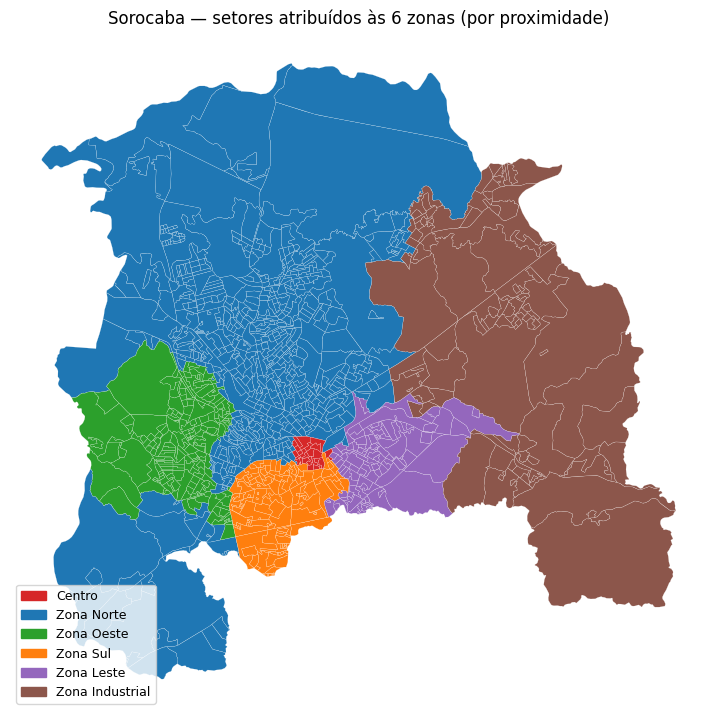


Setores por zona:
  Centro              24
  Zona Norte         594
  Zona Oeste         189
  Zona Sul           127
  Zona Leste         105
  Zona Industrial    109

CSV salvo em /content/setores_por_zona.csv


In [22]:
# 5) Atribui cada setor à sua zona e desenha o mapa
cent = setores.to_crs(3857).geometry.centroid.to_crs(4326)
setores_xy = [(cd, p.x, p.y) for cd, p in zip(setores["CD_SETOR"], cent)]
atrib = atribuir_por_proximidade(setores_xy, pontos)

zona_de = {a["id"]: a["zona"] for a in atrib}
ordem = list(ZONAS.keys())
setores["zona"] = setores["CD_SETOR"].map(zona_de)
setores["_zi"] = setores["zona"].map({z: i for i, z in enumerate(ordem)})

import matplotlib.pyplot as plt, matplotlib.patches as mpatches
fig, ax = plt.subplots(figsize=(9, 9))
# cores fixas por zona: a mesma cor no mapa e na legenda
CORES = {"centro": "#d62728", "norte": "#1f77b4", "oeste": "#2ca02c",
         "sul": "#ff7f0e", "leste": "#9467bd", "industrial": "#8c564b"}
setores.plot(color=setores["zona"].map(CORES).fillna("#cccccc"),
             linewidth=0.12, edgecolor="white", ax=ax)
ax.legend(handles=[mpatches.Patch(color=CORES[z], label=ZONAS[z]["nome"])
                   for z in ordem],
          loc="lower left", fontsize=9, frameon=True)
ax.set_title("Sorocaba — setores atribuídos às 6 zonas (por proximidade)")
ax.set_axis_off(); plt.show()

# tabela: quantos setores por zona
from collections import Counter
c = Counter(a["zona"] for a in atrib)
print("\nSetores por zona:")
for z in ordem:
    print(f"  {ZONAS[z]['nome']:<16} {c.get(z,0):>5}")

# salva o CSV (baixe pelo painel de Arquivos à esquerda, se quiser)
import csv
with open("/content/setores_por_zona.csv", "w", encoding="utf-8", newline="") as f:
    w = csv.writer(f); w.writerow(["CD_SETOR","zona","bairro_mais_proximo","dist_km"])
    for a in atrib: w.writerow([a["id"], a["zona"], a["bairro"], a["dist_km"]])
print("\nCSV salvo em /content/setores_por_zona.csv")